# A small LLM on the GPU — 30 minutes
Qwen2.5-0.5B answers your own strings; then the same requests one by one or in one batch.
Needs a CUDA GPU (Colab: Runtime → Change runtime type → GPU), PyTorch and `transformers`. Download the weights (~1 GB) before class.

In [4]:
# Once, before class, if transformers is missing:
#   Colab / notebook: %pip install "transformers>=4.56,<5" matplotlib
#   local (system Python may refuse pip):
#     python3 -m venv --system-site-packages .venv && .venv/bin/pip install "transformers>=4.56,<5"

In [5]:
import time, statistics
import torch, transformers
import matplotlib.pyplot as plt
from transformers import AutoTokenizer, AutoModelForCausalLM, GenerationConfig

if not torch.cuda.is_available():
    raise RuntimeError("No CUDA GPU: in Colab, Runtime → Change runtime type → GPU.")
transformers.logging.set_verbosity_error()  # hide library warnings
MODEL_ID = "Qwen/Qwen2.5-0.5B-Instruct"
tokenizer = AutoTokenizer.from_pretrained(MODEL_ID, padding_side="left")
model = AutoModelForCausalLM.from_pretrained(MODEL_ID, dtype=torch.float16).to("cuda").eval()

def prepare(strings):  # strings -> token ids on the GPU, padded on the left
    texts = [tokenizer.apply_chat_template([{"role": "user", "content": s}],
                                           tokenize=False, add_generation_prompt=True) for s in strings]
    return tokenizer(texts, padding=True, add_special_tokens=False, return_tensors="pt").to("cuda")

@torch.inference_mode()
def answer_batch(strings, max_tokens=128):
    batch = prepare(strings)
    out = model.generate(**batch, max_new_tokens=max_tokens, do_sample=False,
                         pad_token_id=tokenizer.pad_token_id)
    return tokenizer.batch_decode(out[:, batch["input_ids"].shape[1]:], skip_special_tokens=True)

def answer(string, max_tokens=128):
    return answer_batch([string], max_tokens)[0]

# Timings: the same prompt B times, exactly N_TOKENS new tokens per answer.
PROMPT = "Explain simply why we use computers to do calculations."
N_TOKENS = 32
FIXED = GenerationConfig(max_new_tokens=N_TOKENS, min_new_tokens=N_TOKENS, do_sample=False,
                         eos_token_id=model.generation_config.eos_token_id,
                         pad_token_id=tokenizer.pad_token_id)

@torch.inference_mode()
def generate(batch):
    return model.generate(**batch, generation_config=FIXED, use_model_defaults=False)

def measure(B, repeats=7):  # -> (seconds for one call with B requests, peak GPU memory MiB)
    batch = prepare([PROMPT] * B)
    for _ in range(3):  # warm up (the GPU clock also needs a few calls)
        generate(batch)
    times = []
    torch.cuda.reset_peak_memory_stats()
    for _ in range(repeats):
        torch.cuda.synchronize()
        start = time.perf_counter()
        generate(batch)
        torch.cuda.synchronize()
        times.append(time.perf_counter() - start)
    return round(statistics.median(times), 3), round(torch.cuda.max_memory_allocated() / 2**20)

def one_by_one(n):  # n requests in a row -> time at which each answer is finished
    batch = prepare([PROMPT])
    for _ in range(3):
        generate(batch)
    torch.cuda.synchronize()
    start, finished = time.perf_counter(), []
    for _ in range(n):
        generate(batch)
        torch.cuda.synchronize()
        finished.append(round(time.perf_counter() - start, 3))
    return finished

print(torch.cuda.get_device_name(0), "| torch", torch.__version__, "| transformers", transformers.__version__)
print("prompt length:", prepare([PROMPT])["input_ids"].shape[1], "tokens")

/home/emmanuel/.local/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


NVIDIA RTX 1000 Ada Generation Laptop GPU | torch 2.11.0+cu130 | transformers 4.57.6
prompt length: 40 tokens


## 1. Your own strings

In [31]:
print(answer("Explain in two sentences why we group computations on a GPU."))

Grouping computations on a GPU allows for parallel processing of tasks across multiple cores and threads, significantly reducing the time required to complete operations such as matrix multiplication or image processing. This approach is particularly useful when dealing with large datasets or complex algorithms that require significant computational resources. By leveraging the power of GPUs, developers can achieve faster


In [87]:
print(answer("Explain in two sentences why we group computations on a GPU."))

Grouping computations on a GPU allows for parallel processing of tasks across multiple cores and threads, significantly reducing the time required to complete operations such as matrix multiplication or image processing. This approach is particularly useful when dealing with large datasets or complex algorithms that require significant computational resources. By leveraging the power of GPUs, developers can achieve faster


In [61]:
answer_batch(["Translate into French: the cat sleeps on the sofa.",
              "What is 7 times 8? Answer in one sentence."])

['Le chat dort sur la chaise.', 'The answer to "7 times 8" is 56.']

## 2. One request, then a batch
Timed: one `generate` call on token ids already on the GPU (prompt + 32 new tokens), until the GPU has finished.

In [8]:
measure(1)

(0.396, 965)

In [9]:
measure(8)

(0.443, 993)

In [10]:
one_by_one(8)

[0.388, 0.789, 1.18, 1.583, 1.988, 2.392, 2.793, 3.196]

Your turn: new tokens per second and seconds per answer, for B answers of `N_TOKENS` tokens.

In [11]:
def rates(B, seconds):
    ## SOLUTION: return (new tokens per second, seconds per answer) ##
    return B * N_TOKENS / seconds, seconds / B
    ## END ##

assert rates(8, 2.0) == (128.0, 0.25)
rates(8, measure(8)[0])

(638.4039900249376, 0.050125)

## 3. The whole table

In [12]:
rows = []
print("  B | seconds | tokens/s | s/answer | peak MiB")
for B in [1, 2, 4, 8, 16, 32, 64, 128]:
    try:
        seconds, mib = measure(B)
    except torch.cuda.OutOfMemoryError:
        print("out of GPU memory at B =", B)
        break
    finally:
        torch.cuda.empty_cache()
    tokens_per_s, per_answer = rates(B, seconds)
    rows.append((B, seconds, tokens_per_s, mib))
    print(f"{B:3d} | {seconds:7.3f} | {tokens_per_s:8.0f} | {per_answer:8.3f} | {mib:8d}")

  B | seconds | tokens/s | s/answer | peak MiB
  1 |   0.399 |       80 |    0.399 |      965
  2 |   0.411 |      156 |    0.205 |      969
  4 |   0.416 |      308 |    0.104 |      977
  8 |   0.429 |      597 |    0.054 |      993
 16 |   0.437 |     1172 |    0.027 |     1025
 32 |   0.501 |     2044 |    0.016 |     1090
 64 |   0.636 |     3220 |    0.010 |     1239
128 |   0.960 |     4267 |    0.007 |     1477


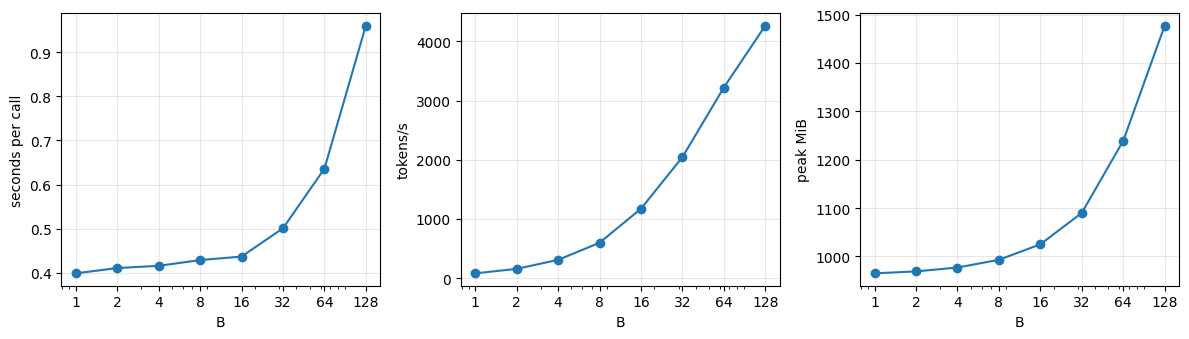

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.5))
for ax, k, label in zip(axes, [1, 2, 3], ["seconds per call", "tokens/s", "peak MiB"]):
    ax.plot([r[0] for r in rows], [r[k] for r in rows], "o-")
    ax.set(xscale="log", xlabel="B", ylabel=label)
    ax.set_xticks([r[0] for r in rows], [str(r[0]) for r in rows])
    ax.grid(alpha=0.3)
fig.tight_layout()